# Soul mates with Bayes, on simulated data

Everyone has one soul mate, drawn at random from the M people born within 5 years of them. You find them
only if you meet and talk to them and you both recognize each other. This notebook estimates how many new
people of your own age you meet per day, turns that into new people met between 15 and 60, and then into
the chance of finding your soul mate. The data is simulated with known true values, so we can check the model.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pymc as pm

from soulmates.model import age_band, build_model, p_find
from soulmates.simulate import simulate_diaries

# Made up true values: mean new contacts per day for each 5 year band, peaking at ages 20 to 24
TRUE_BAND_MEANS = [1.0, 1.5, 2.0, 3.0, 4.0, 3.5, 3.0, 2.5, 2.5, 2.0, 2.0, 1.5, 1.5, 1.0, 1.0, 1.0, 1.0]
TRUE_ALPHA = 0.2
TRUE_WEEKEND = 1.4
TRUE_COUNTRY_FACTORS = [0.5, 0.8, 1.25, 2.0]  # four made up countries, from quiet to talkative
df = simulate_diaries(6000, TRUE_BAND_MEANS, TRUE_ALPHA, seed=1, weekend_effect=TRUE_WEEKEND,
                      country_factors=TRUE_COUNTRY_FACTORS)
df.head()

,age,new_contacts,weekend,country
0,40,0,True,C0
1,43,0,False,C1
2,64,0,False,C2
3,80,3,False,C3
4,2,1,False,C3


country
C0    1.04
C1    1.72
C2    2.80
C3    4.17
Name: new_contacts, dtype: float64

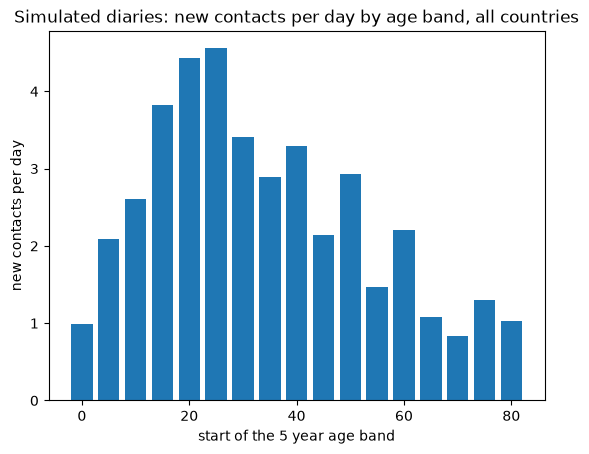

In [2]:
observed = df.groupby(age_band(df["age"]))["new_contacts"].mean()
fig, ax = plt.subplots()
ax.bar(observed.index * 5, observed.values, width=4)
ax.set(xlabel="start of the 5 year age band", ylabel="new contacts per day",
       title="Simulated diaries: new contacts per day by age band, all countries")
df.groupby("country")["new_contacts"].mean().round(2)

## Prior predictive check

Before fitting, we draw fake diaries from the priors alone. They should cover the simulated diaries
without putting much weight on absurd days.

Sampling: [alpha, beta_weekend, log_factor, mu_pop, new_contacts, p_recog, sigma_band, sigma_country, z, z_new]


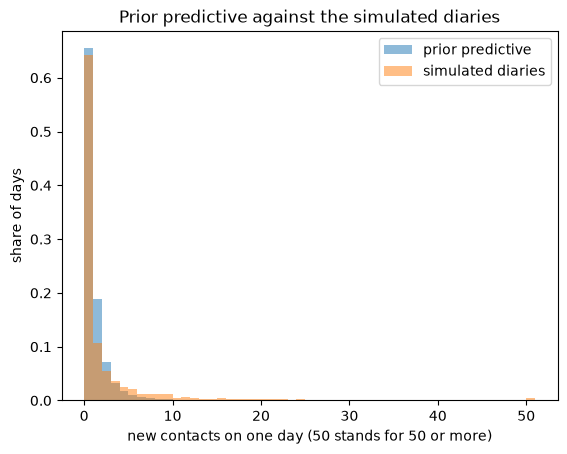

In [3]:
model = build_model(df)
with model:
    prior = pm.sample_prior_predictive(random_seed=3)
prior_counts = prior.prior_predictive["new_contacts"].values.ravel()
bins = np.arange(52)
fig, ax = plt.subplots()
ax.hist(np.minimum(prior_counts, 50), bins=bins, density=True, alpha=0.5, label="prior predictive")
ax.hist(np.minimum(df["new_contacts"], 50), bins=bins, density=True, alpha=0.5, label="simulated diaries")
ax.set(xlabel="new contacts on one day (50 stands for 50 or more)", ylabel="share of days",
       title="Prior predictive against the simulated diaries")
ax.legend();

## Fit and recovery

The model has a level for each age band and a factor for each country. The posterior should sit close
to the true values.

In [4]:
with model:
    idata = pm.sample(random_seed=2)
az.summary(idata, var_names=["mu_pop", "sigma_band", "sigma_country", "alpha", "beta_weekend", "lifetime_typical"])

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu_pop, sigma_band, z, sigma_country, log_factor, beta_weekend, alpha, z_new, p_recog]


/Users/a.jebari/Desktop/Study/soulmates/.venv/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 16 seconds.


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu_pop,0.508,0.139,0.28,0.73,811,1263,1.01,0.0049,0.0033
sigma_band,0.533,0.098,0.39,0.7,1169,1735,1.00,0.0029,0.0019
sigma_country,0.601,0.201,0.35,0.97,4927,3062,1.00,0.003,0.0047
alpha,0.1874,0.0054,0.18,0.2,4773,2353,1.00,7.9e-05,9.2e-05
beta_weekend,0.379,0.07,0.27,0.49,4418,2573,1.00,0.001,0.0014
lifetime_typical,4.74e+04,2.08e+03,44000,51000,4217,3774,1.00,32,27


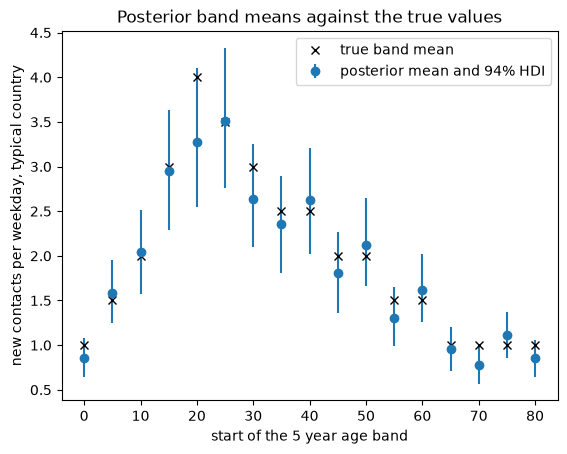

In [5]:
hdi = az.hdi(idata, var_names=["band_mean"], prob=0.94)["band_mean"].values
mean = idata.posterior["band_mean"].mean(("chain", "draw")).values
ages = np.arange(17) * 5
fig, ax = plt.subplots()
ax.errorbar(ages, mean, yerr=[mean - hdi[:, 0], hdi[:, 1] - mean], fmt="o", label="posterior mean and 94% HDI")
ax.plot(ages, TRUE_BAND_MEANS, "kx", label="true band mean")
ax.set(xlabel="start of the 5 year age band", ylabel="new contacts per weekday, typical country",
       title="Posterior band means against the true values")
ax.legend();

In [6]:
factor = idata.posterior["country_factor"]
for name, true in zip(factor["country"].values, TRUE_COUNTRY_FACTORS):
    draws = factor.sel(country=name).values.ravel()
    print(f"{name}: true factor {true}, posterior {draws.mean():.2f} "
          f"({np.percentile(draws, 3):.2f} to {np.percentile(draws, 97):.2f})")

C0: true factor 0.5, posterior 0.50 (0.45 to 0.55)
C1: true factor 0.8, posterior 0.83 (0.75 to 0.92)
C2: true factor 1.25, posterior 1.28 (1.15 to 1.42)
C3: true factor 2.0, posterior 1.89 (1.70 to 2.09)


## The chance of finding your soul mate

P_find = 1 − (1 − p_recog / M) ^ lifetime. The pool M is made up here, because the data is simulated.
`lifetime_anywhere` is the count for a person in a country we have no data for.

P_find mean 3.49e-04, 94% interval 6.34e-05 to 9.58e-04


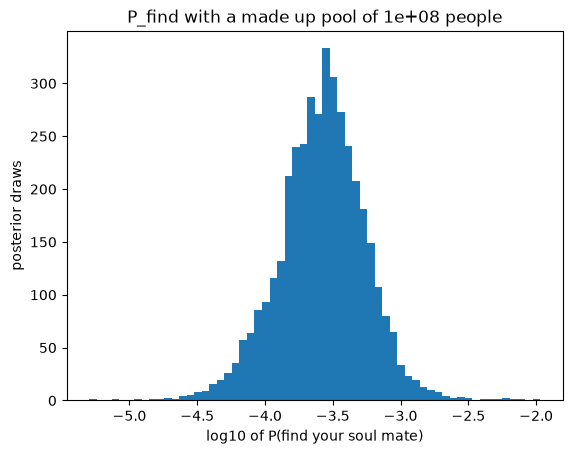

In [7]:
POOL_SIZE = 1e8  # made up, the real pool comes from the UN data in notebook 02
pf = p_find(idata, POOL_SIZE).values.ravel()
fig, ax = plt.subplots()
ax.hist(np.log10(pf), bins=60)
ax.set(xlabel="log10 of P(find your soul mate)", ylabel="posterior draws",
       title=f"P_find with a made up pool of {POOL_SIZE:.0e} people")
print(f"P_find mean {pf.mean():.2e}, 94% interval {np.percentile(pf, 3):.2e} to {np.percentile(pf, 97):.2e}")